# ЛР №4. ML-классификация стилей игроков и сегментация
**Печенов В. В., ИВТ-465 · 17.11.2026**

Данные синтетические: это демонстрация метода, не исследование реальных пользователей.
Цель: выделить поведенческие сегменты и предсказать отсутствие возврата в дни 21–30.
Признаки доступны только до конца дня 20. Разбиение по игрокам: 60/20/20.
Archetype, churned и идентификаторы не попадают в матрицу признаков.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display
from lab04.experiment import run
from lab04.features import player_features, churn_labels
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
audit = run(ROOT)
df = pd.read_csv(ROOT / 'data/events.csv')
print('Игроков:', audit['players'], 'Сессий:', len(df), 'Churn:', round(audit['churn_rate'], 3))
display(df.head())

Игроков: 1500 Сессий: 24980 Churn: 0.441


,player_id,session_id,day,hour,length_s,kills,deaths,explored,chats,archetype,churned
0,p0000,p0000_s000,3,10,216.088,10,5,0.29928,0,aggressive,1
1,p0000,p0000_s001,8,7,298.033,11,0,0.27313,2,aggressive,1
2,p0000,p0000_s002,11,5,243.028,10,4,0.17644,0,aggressive,1
3,p0000,p0000_s003,13,3,318.505,6,4,0.28572,1,aggressive,1
4,p0000,p0000_s004,16,13,236.177,11,3,0.28475,1,aggressive,1


## 1. Датасет и контроль качества
1500 игроков, три стиля: aggressive, explorer, social. Непрерывная скрытая вовлечённость
влияет на частоту и длительность сессий, а также вероятность будущего возврата.
Она не записывается в таблицу и не подаётся модели. У каждого игрока есть хотя бы одна
сессия в окне наблюдения; нулевые истории вне области этой модели.
Метка вычисляется из событий будущего окна, а не из признака last_day.

In [2]:
assert df.session_id.is_unique
assert df.notna().all().all()
assert df.day.between(0, 30).all()
X = player_features(df)
y = churn_labels(df, X.index)
assert X.shape == (1500, 16)
assert not {'archetype', 'churned', 'player_id', 'cluster'}.intersection(X.columns)
assert X.last_day.le(20).all()
display(df.groupby('archetype').agg(players=('player_id', 'nunique'), sessions=('session_id', 'count')))
display(X.describe().T.round(3))

,players,sessions
archetype,,
aggressive,493,8154
explorer,484,8120
social,523,8706


,count,mean,std,min,25%,50%,75%,max
n_sessions,1500.0,13.926,8.924,1.000,8.000,12.000,18.000,80.000
avg_len,1500.0,545.833,247.486,100.797,370.603,502.822,671.005,2127.838
total_len,1500.0,9513.314,12161.875,181.918,2862.058,5894.845,11398.036,170227.045
kills_per_session,1500.0,4.665,3.143,0.250,2.229,3.000,8.337,13.429
deaths_per_session,1500.0,2.979,0.969,0.667,2.167,3.000,3.685,6.071
kd_ratio,1500.0,1.468,0.687,0.286,0.938,1.211,2.054,4.143
explored_mean,1500.0,0.530,0.242,0.181,0.269,0.498,0.830,0.930
chats_per_session,1500.0,4.795,4.583,0.000,1.188,2.000,10.353,16.333
active_days,1500.0,9.487,3.941,1.000,6.750,9.000,12.000,21.000
last_day,1500.0,18.575,2.056,3.000,18.000,19.000,20.000,20.000


## 2. Признаки (16)
Базовые: число сессий; среднее/суммарное время; убийства и смерти за сессию;
сглаженное K/D; исследование; чаты; активные дни; последний день; сессии на активный день.
Добавлены: стандартное отклонение длительности, доля ночных сессий (00:00–05:59),
линейный тренд длительности по дням, нормированный тренд активности (дни 0–10 против 11–20),
recency = 20 - last_day. При одной сессии или одном уникальном дне тренд и std равны 0.
Коррелированные признаки допустимы, но разделяют между собой permutation importance.

## 3. Кластеры и 2D
KMeans обучается на пяти стандартизованных признаках стиля: kills_per_session,
deaths_per_session, kd_ratio, explored_mean, chats_per_session. Активность не включена,
чтобы разделять стиль игры, а не степень вовлечённости. Проверяем k=2..7 и выбираем
максимум silhouette. PCA применяется к тем же данным только для визуализации.
Названия даются по центрам кластеров; archetype используется только для внешней проверки ARI.

Выбрано k: 3 ARI: 1.0
Доля дисперсии двух PCA-компонент: 0.9044880180507576


,cluster,n_sessions,avg_len,total_len,kills_per_session,deaths_per_session,kd_ratio,explored_mean,chats_per_session,active_days,last_day,sessions_per_active_day,len_std,night_share,length_trend,activity_trend,recency,players,share,name
0,0,13.849,545.659,9301.772,2.991,3.003,1.027,0.500,10.960,9.547,18.604,1.374,238.227,0.258,1.642,0.015,1.396,523,0.349,Социальные
1,1,13.862,543.303,9417.983,9.012,3.944,2.307,0.252,1.008,9.424,18.505,1.385,239.309,0.253,2.845,0.039,1.495,493,0.329,Бойцы
2,2,14.074,548.598,9839.007,2.044,1.969,1.090,0.847,1.991,9.488,18.614,1.397,241.090,0.260,2.985,0.049,1.386,484,0.323,Исследователи


,cluster,aggressive,explorer,social
0,0,0,0,523
1,1,493,0,0
2,2,0,484,0


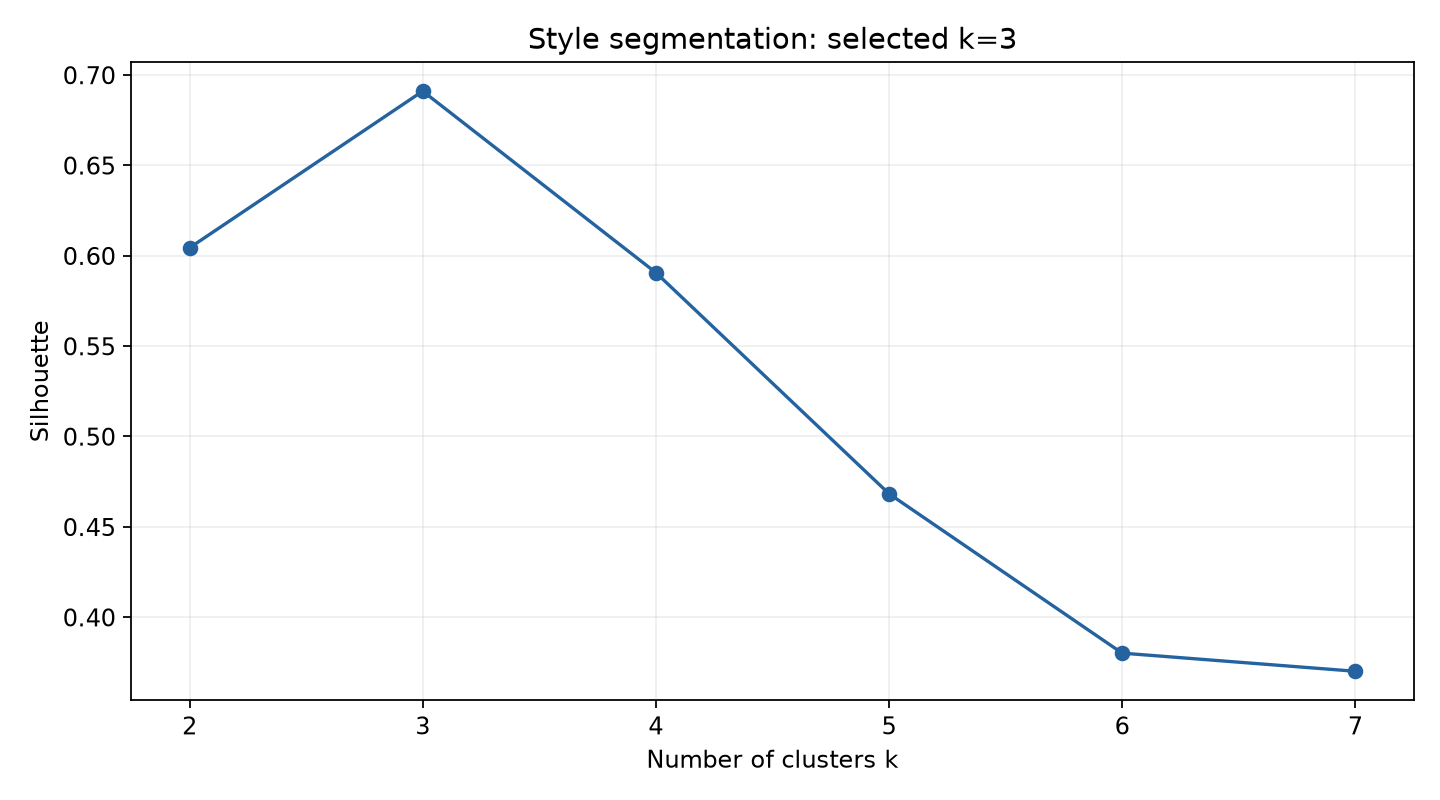

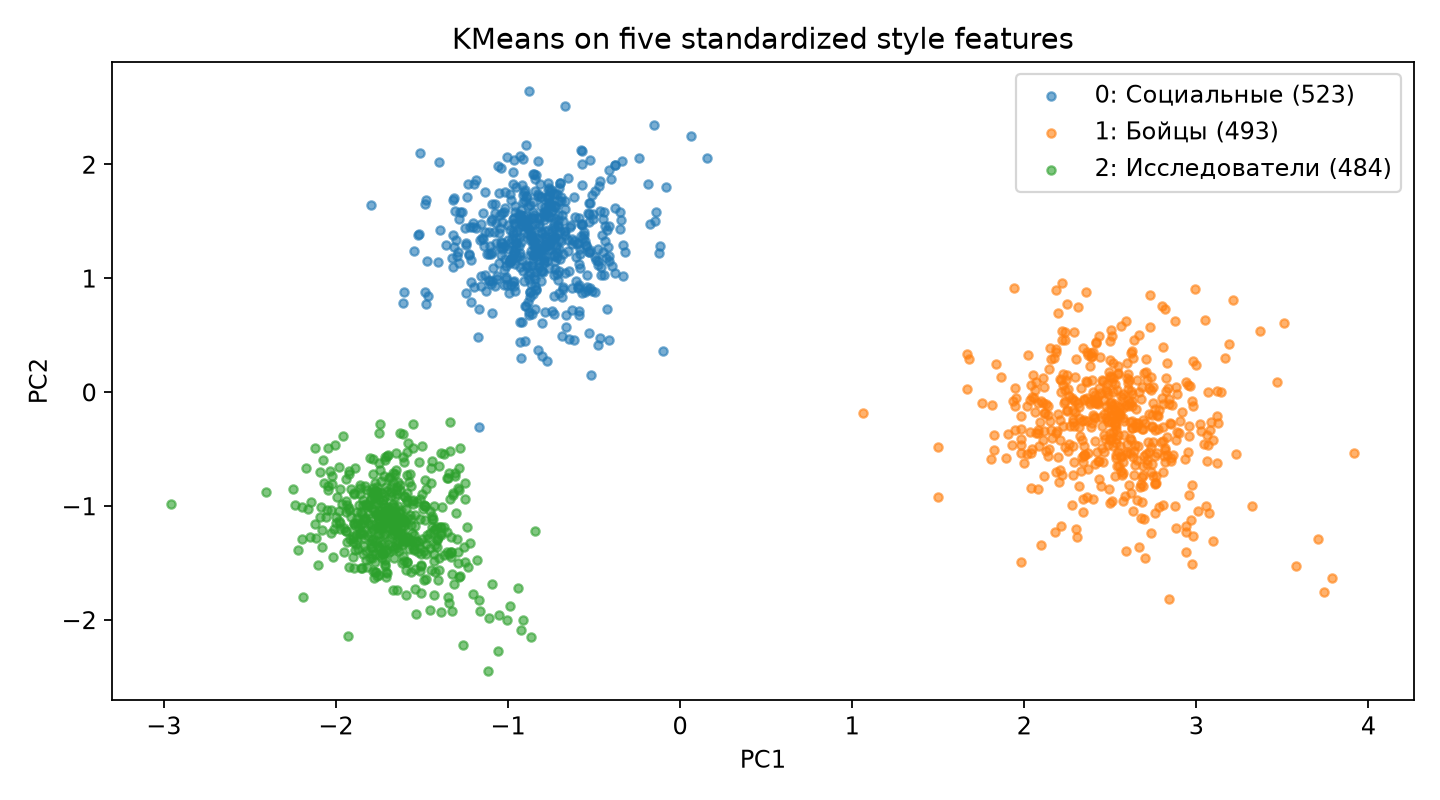

In [3]:
print('Выбрано k:', audit['k'], 'ARI:', round(audit['ari'], 4))
print('Доля дисперсии двух PCA-компонент:', sum(audit['pca_variance']))
display(pd.read_csv(ROOT / 'results/cluster_profiles.csv').round(3))
display(pd.read_csv(ROOT / 'results/cluster_vs_archetype.csv'))
display(Image(filename=str(ROOT / 'results/silhouette.png')))
display(Image(filename=str(ROOT / 'results/clusters_pca.png')))

Интерпретация: «Бойцы» чаще убивают, «Исследователи» имеют наибольшее explored_mean,
«Социальные» чаще общаются. Эти сегменты можно использовать для боевых испытаний,
исследовательских заданий и кооперативных событий соответственно. Высокий ARI ожидаем
на синтетических архетипах; на реальных данных столь чистые границы не гарантированы.

## 4. Прогноз ухода: train / validation / test
Фиксируем seed=42; стратификация по метке на уровне игрока, 900/300/300 человек.
StandardScaler логистической регрессии обучается только на train в Pipeline.
Сравниваем Dummy(prior), LogisticRegression(C=1), RandomForest(300 деревьев,
min_samples_leaf=5). Выбор между LR/RF делается по validation ROC-AUC, затем один раз
оценивается test; параметры не подбираются по test. Модели оставлены обученными на train.
Top-20% — precision среди 60 тестовых игроков с самым высоким риском.
500 bootstrap-перевыборок test дают условный 95% интервал AUC выбранной модели.

,validation_auc,test_auc,precision_top20
model,,,
Dummy,0.500,0.5000,0.4167
LogisticRegression,0.869,0.9127,0.9833
RandomForest,0.864,0.9121,0.9500


Выбрана по validation: LogisticRegression
95% bootstrap CI: [0.8822689208050065, 0.9399064953407152]


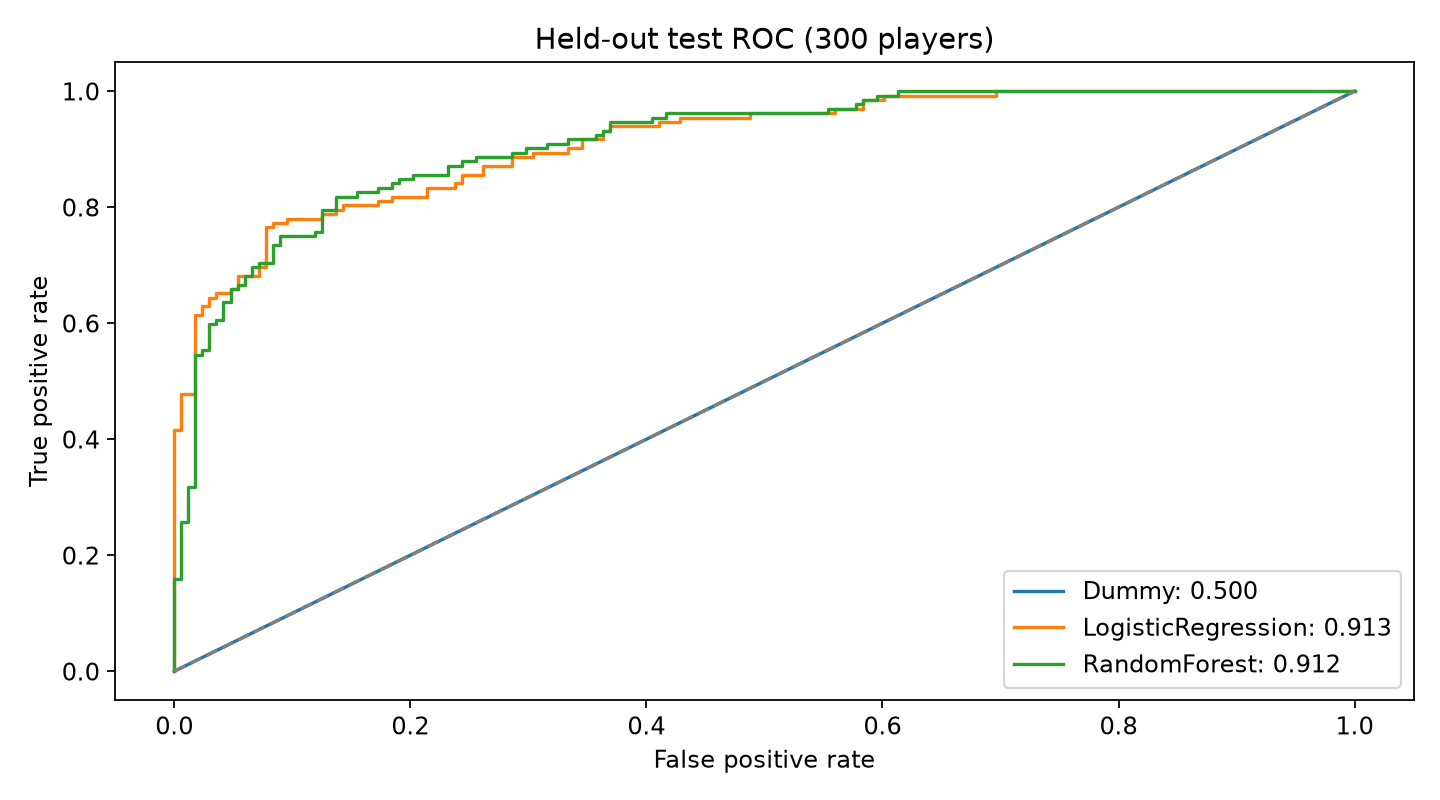

In [4]:
metrics = pd.DataFrame(audit['metrics']).set_index('model')
display(metrics.round(4))
print('Выбрана по validation:', audit['selected'])
print('95% bootstrap CI:', audit['auc_ci95'])
selected_auc = metrics.loc[audit['selected'], 'test_auc']
assert selected_auc >= 0.70
display(Image(filename=str(ROOT / 'results/roc.png')))

### Контроль утечки
Намеренно нарушаем границу времени: last_day из дней 0–30 подаётся отдельной LR.
Тестовые игроки те же. Метка «нет сессий в 21–30» почти дословно кодируется этим
признаком, поэтому AUC близко к 1. Это недопустимая модель для прогноза на день 20.
Честная модель использует last_day только из окна 0–20.

In [5]:
display(pd.DataFrame([
    {'experiment': 'Честная модель (0–20)', 'test_auc': float(selected_auc)},
    {'experiment': 'Утечка last_day (0–30)', 'test_auc': audit['leaky_auc']}
]))
# Независимое подтверждение метки по будущим событиям
assert y.equals(df.groupby('player_id').churned.first().loc[X.index].rename('churned'))

,experiment,test_auc
0,Честная модель (0–20),0.912698
1,Утечка last_day (0–30),1.000000


## 5. Важность признаков
Permutation importance: уменьшение тестового ROC-AUC при перестановке одного признака,
15 повторов; полосы показывают стандартное отклонение. Объясняем уже выбранную модель,
не отбираем по этому графику признаки. Это статистическая ассоциация, не причинный эффект.

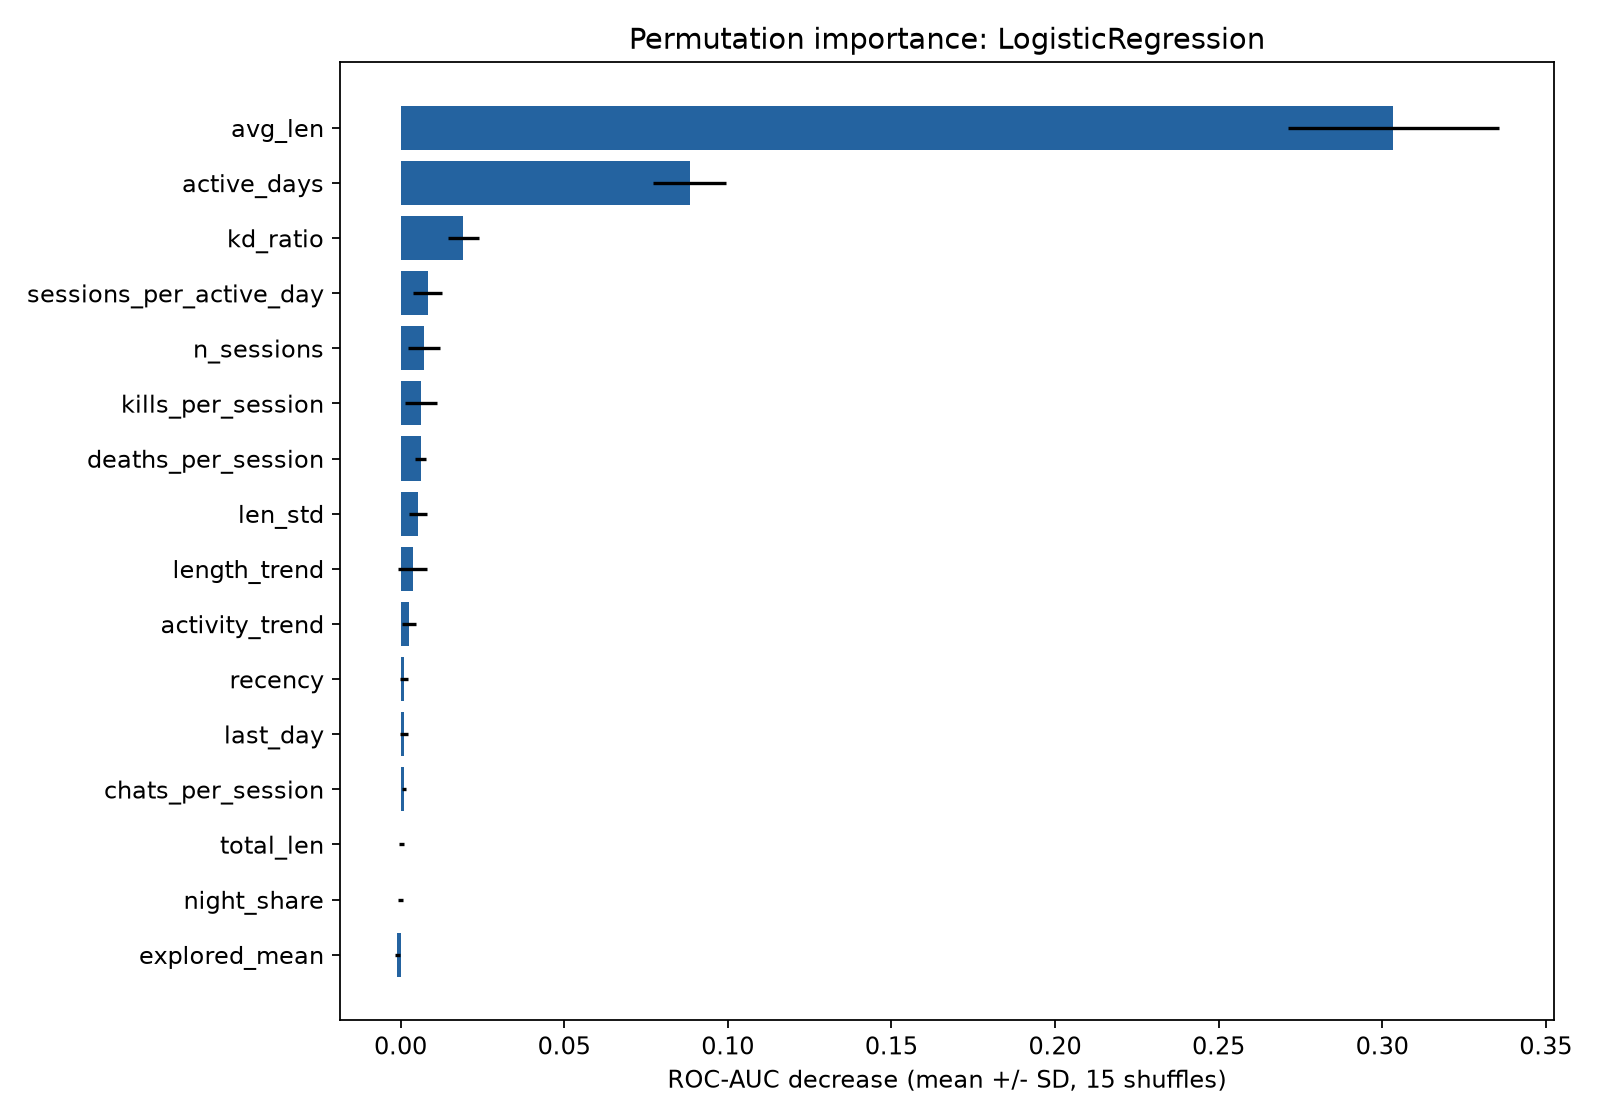

,feature,mean,std
15,avg_len,0.303442,0.032282
14,active_days,0.088357,0.011149
13,kd_ratio,0.019132,0.004762
12,sessions_per_active_day,0.008327,0.004383
11,n_sessions,0.007308,0.004882
10,kills_per_session,0.006205,0.004974
9,deaths_per_session,0.006136,0.001587
8,len_std,0.005303,0.002844


Версии: {'numpy': '2.5.5', 'pandas': '3.1.1', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2'}


In [6]:
display(Image(filename=str(ROOT / 'results/feature_importance.png')))
display(pd.read_csv(ROOT / 'results/feature_importance.csv').sort_values('mean', ascending=False).head(8))
print('Версии:', audit['versions'])

## Выводы и ограничения
Выполнены сегментация, интерпретация, прогноз ухода и контроль утечки.
Вероятности ухода полезны для ранжирования предложений удержания, но эффект акций
нужно проверять отдельным A/B-тестом. Данные созданы одной моделью генерации и одним seed;
высокие оценки не доказывают качество на реальной игре. Нужны внешняя временная проверка,
мониторинг сдвига распределений, калибровка вероятностей и оценка цены ошибок.

Повтор: `python -m lab04.experiment`; проверки: `python -m pytest`, `python -m ruff check .`.
Источники и полный отчёт: `docs/report.md`, `docs/report.pdf`.